# PCS3838 Inteligência Artificial: Classificação de Textos com Transformers

| Nome | Número USP |
|---|---|
| André Moreno | 13682785 |
| Giovani Sebastianutti | 13680171 |
| Matheus Guidoni | 12683120 |

Dataset: Emotion Dataset (Saravia et al., 2018), tweets em inglês com 6 emoções.

Fluxo: três encoders congelados (BERT, RoBERTa, DeBERTa-v3) geram um vetor por texto. Sobre esses vetores treinamos Regressão Logística e MLP, avaliados com validação cruzada estratificada de 5 folds, sempre com os mesmos folds.

Os embeddings, os modelos de cada fold e as predições de validação ficam salvos em `embeddings/`, `models/` e `results/`. Ao reexecutar, o que já existe em disco é carregado em vez de recalculado.

## 1. Configuração

In [1]:
import os
os.environ["USE_TF"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoModel, AutoTokenizer

/home/andre/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


/home/andre/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
DATA = Path("data")
EMB, MODELS, RESULTS = Path("embeddings"), Path("models"), Path("results")
for d in (EMB, MODELS, RESULTS):
    d.mkdir(exist_ok=True)

CLASSES = ["sadness", "joy", "love", "anger", "fear", "surprise"]
ENCODERS = {
    "BERT": "bert-base-uncased",
    "RoBERTa": "roberta-base",
    "DeBERTa-v3": "microsoft/deberta-v3-base",
}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE

'cuda'

## 2. Dados

O dataset vem dividido em treino (16.000), validação (2.000) e teste (2.000). Como a avaliação pedida é por validação cruzada, juntamos as três partes em um único conjunto de 20.000 textos e deixamos o `StratifiedKFold` criar as partições.

In [3]:
df = pd.concat([pd.read_csv(DATA / f) for f in ("training.csv", "validation.csv", "test.csv")], ignore_index=True)
texts, y = df["text"].tolist(), df["label"].to_numpy()
df.shape

(20000, 2)

In [4]:
df.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


In [5]:
counts = df["label"].value_counts().sort_index()
pd.DataFrame({"classe": CLASSES, "n": counts.values, "%": (100 * counts / len(df)).round(2).values})

,classe,n,%
0,sadness,5797,28.98
1,joy,6761,33.80
2,love,1641,8.20
3,anger,2709,13.54
4,fear,2373,11.86
5,surprise,719,3.60


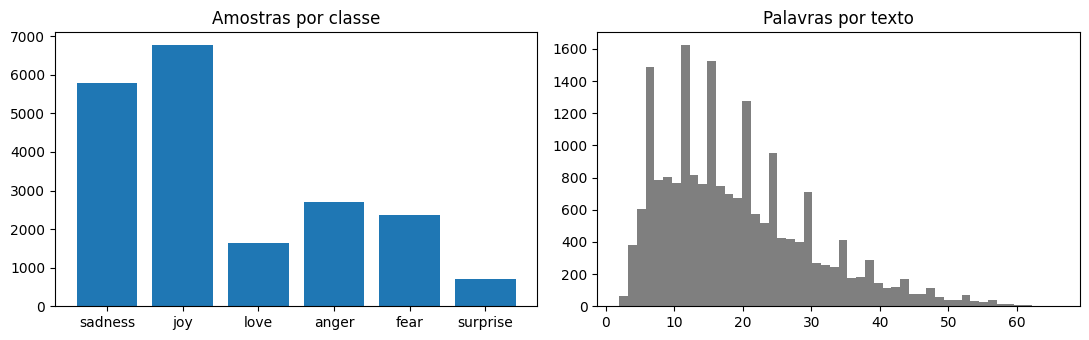

count    20000.000000
mean        19.135050
std         10.972016
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: text, dtype: float64

In [6]:
lengths = df["text"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(CLASSES, counts.values, color="tab:blue")
axes[0].set_title("Amostras por classe")
axes[1].hist(lengths, bins=50, color="tab:gray")
axes[1].set_title("Palavras por texto")
plt.tight_layout()
plt.show()
lengths.describe()

As classes são desbalanceadas (`joy` e `sadness` somam cerca de 63%, `surprise` tem só 3,6%). Isso justifica a estratificação dos folds e o uso de métricas com média macro, que dão o mesmo peso a cada classe.

Os textos são curtos (no máximo 66 palavras), então truncar em 128 tokens não descarta conteúdo.

## 3. Folds fixos

Os índices dos 5 folds são gerados uma vez com semente fixa, salvos em disco e reutilizados em todas as seis configurações.

In [7]:
folds_path = RESULTS / "folds.npy"
if folds_path.exists():
    fold_id = np.load(folds_path)
else:
    fold_id = np.empty(len(y), dtype=int)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for k, (_, val_idx) in enumerate(skf.split(np.zeros(len(y)), y)):
        fold_id[val_idx] = k
    np.save(folds_path, fold_id)

FOLDS = [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(5)]
pd.crosstab(fold_id, df["label"].map(dict(enumerate(CLASSES))), margins=True)

label,anger,fear,joy,love,sadness,surprise,All
row_0,,,,,,,
0,542,474,1352,328,1160,144,4000
1,541,475,1352,329,1160,143,4000
2,542,475,1352,328,1159,144,4000
3,542,475,1352,328,1159,144,4000
4,542,474,1353,328,1159,144,4000
All,2709,2373,6761,1641,5797,719,20000


## 4. Embeddings dos encoders congelados

Cada encoder roda apenas em modo de inferência (`eval()` e `torch.no_grad()`), sem nenhuma atualização de pesos.

Vetor por texto: média dos estados ocultos da última camada (mean pooling), considerando só os tokens reais via `attention_mask`. Escolhemos a média em vez do token `[CLS]`/`<s>` porque, sem ajuste fino, o `[CLS]` desses modelos não é treinado para resumir a frase (no RoBERTa e no DeBERTa-v3 ele nem tem objetivo próprio no pré-treino), enquanto a média agrega a informação de todas as palavras.

Resultado: uma matriz 20.000 × 768 por encoder, salva em `embeddings/`.

Observação: ao carregar o tokenizador do DeBERTa-v3, a versão 4.57 do Transformers emite um aviso sobre "incorrect regex pattern". Conferimos que o tokenizador rápido e o original (SentencePiece, `use_fast=False`) produzem exatamente os mesmos ids nos 2.000 primeiros textos, então o aviso não afeta os resultados.

In [8]:
@torch.no_grad()
def embed(model_name, texts, batch_size=64, max_length=128):
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    out = []
    for i in range(0, len(texts), batch_size):
        batch = tok(texts[i:i + batch_size], padding=True, truncation=True, max_length=max_length, return_tensors="pt").to(DEVICE)
        h = model(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).to(h.dtype)
        out.append(((h * mask).sum(1) / mask.sum(1)).cpu().numpy())
    del model
    torch.cuda.empty_cache()
    return np.concatenate(out)

In [9]:
X = {}
for name, hf_name in ENCODERS.items():
    path = EMB / f"{name}.npy"
    if not path.exists():
        np.save(path, embed(hf_name, texts))
    X[name] = np.load(path)
    print(f"{name:11s} {hf_name:28s} {X[name].shape}")

BERT        bert-base-uncased            (20000, 768)


RoBERTa     roberta-base                 (20000, 768)


DeBERTa-v3  microsoft/deberta-v3-base    (20000, 768)


## 5. Classificadores

Ambos recebem os vetores padronizados (`StandardScaler`, ajustado só no treino de cada fold, dentro de um `Pipeline`, para não vazar informação da validação).

- **Regressão Logística**: multinomial, solver `lbfgs`, regularização L2 com `C=1.0` (padrão) e `max_iter=3000` para garantir convergência em 768 dimensões. É a sonda linear clássica: mede o quanto a emoção está linearmente disponível na representação.
- **MLP**: uma camada oculta de 256 neurônios ReLU, Adam, `alpha=1e-3` (L2), `early_stopping=True` com 10% do treino do fold como validação interna e paciência de 10 épocas, `max_iter=300`. Uma camada é suficiente para capturar interações não lineares e o early stopping controla o sobreajuste sem usar o fold de validação.

Não usamos ajuste de hiperparâmetros por busca, para manter as seis configurações comparáveis e o custo baixo. Também não usamos `class_weight` porque o `MLPClassifier` não oferece essa opção e queremos os dois classificadores nas mesmas condições.

In [10]:
CLASSIFIERS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED)),
    "MLP": lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-3, early_stopping=True, n_iter_no_change=10, max_iter=300, random_state=SEED)),
}

## 6. Validação cruzada

Para cada uma das 6 configurações e cada fold: treina no restante, prediz o fold de validação e calcula acurácia, precisão, recall e F1 em média macro. As predições de validação dos 5 folds (out-of-fold) cobrem os 20.000 textos e alimentam as matrizes de confusão. Os modelos treinados de cada fold são salvos em `models/`.

In [11]:
def run_cv(enc, clf):
    pred_path = RESULTS / f"oof_{enc}_{clf}.npy"
    if pred_path.exists():
        return np.load(pred_path)
    oof = np.empty_like(y)
    for k, (tr, va) in enumerate(FOLDS):
        model_path = MODELS / f"{enc}_{clf}_fold{k}.joblib"
        if model_path.exists():
            model = joblib.load(model_path)
        else:
            model = CLASSIFIERS[clf]().fit(X[enc][tr], y[tr])
            joblib.dump(model, model_path)
        oof[va] = model.predict(X[enc][va])
    np.save(pred_path, oof)
    return oof

In [12]:
def fold_metrics(oof):
    rows = []
    for k, (_, va) in enumerate(FOLDS):
        p, r, f, _ = precision_recall_fscore_support(y[va], oof[va], average="macro", zero_division=0)
        rows.append({"fold": k + 1, "acurácia": accuracy_score(y[va], oof[va]), "precisão": p, "recall": r, "F1": f})
    return pd.DataFrame(rows).set_index("fold")

In [13]:
%%time
OOF, METRICS = {}, {}
for enc in ENCODERS:
    for clf in CLASSIFIERS:
        cfg = f"{enc} + {clf}"
        OOF[cfg] = run_cv(enc, clf)
        METRICS[cfg] = fold_metrics(OOF[cfg])
        print(f"{cfg:22s} F1 macro = {METRICS[cfg]['F1'].mean():.4f}")

BERT + LogReg          F1 macro = 0.5472
BERT + MLP             F1 macro = 0.5584
RoBERTa + LogReg       F1 macro = 0.5614
RoBERTa + MLP          F1 macro = 0.5685
DeBERTa-v3 + LogReg    F1 macro = 0.4718
DeBERTa-v3 + MLP       F1 macro = 0.4429
CPU times: user 138 ms, sys: 8.52 ms, total: 146 ms
Wall time: 145 ms


## 7. Resultados por configuração

Métricas por fold (precisão, recall e F1 em média macro), seguidas de média e desvio-padrão amostral entre folds.

In [14]:
def with_summary(m):
    return pd.concat([m, m.agg(["mean", "std"]).rename(index={"mean": "média", "std": "desvio"})])

### BERT + LogReg

In [15]:
with_summary(METRICS["BERT + LogReg"]).round(4)

,acurácia,precisão,recall,F1
1,0.6370,0.5639,0.5398,0.5493
2,0.6360,0.5680,0.5440,0.5531
3,0.6398,0.5695,0.5358,0.5494
4,0.6268,0.5407,0.5245,0.5311
5,0.6378,0.5613,0.5466,0.5529
média,0.6355,0.5607,0.5381,0.5472
desvio,0.0051,0.0116,0.0086,0.0092


### BERT + MLP

In [16]:
with_summary(METRICS["BERT + MLP"]).round(4)

,acurácia,precisão,recall,F1
1,0.6560,0.5933,0.5668,0.5776
2,0.6358,0.5674,0.5361,0.5488
3,0.6442,0.5746,0.5332,0.5486
4,0.6492,0.5926,0.5423,0.5616
5,0.6420,0.5731,0.5446,0.5554
média,0.6454,0.5802,0.5446,0.5584
desvio,0.0076,0.0119,0.0132,0.0120


### RoBERTa + LogReg

In [17]:
with_summary(METRICS["RoBERTa + LogReg"]).round(4)

,acurácia,precisão,recall,F1
1,0.6435,0.5681,0.5461,0.5555
2,0.6405,0.5717,0.5582,0.5633
3,0.6595,0.5877,0.5654,0.5748
4,0.6470,0.5708,0.5551,0.5615
5,0.6325,0.5624,0.5438,0.5520
média,0.6446,0.5721,0.5537,0.5614
desvio,0.0099,0.0094,0.0089,0.0088


### RoBERTa + MLP

In [18]:
with_summary(METRICS["RoBERTa + MLP"]).round(4)

,acurácia,precisão,recall,F1
1,0.6602,0.6040,0.5651,0.5805
2,0.6498,0.5963,0.5515,0.5692
3,0.6675,0.6069,0.5685,0.5841
4,0.6418,0.5802,0.5220,0.5434
5,0.6508,0.5853,0.5546,0.5654
média,0.6540,0.5946,0.5523,0.5685
desvio,0.0100,0.0116,0.0184,0.0160


### DeBERTa-v3 + LogReg

In [19]:
with_summary(METRICS["DeBERTa-v3 + LogReg"]).round(4)

,acurácia,precisão,recall,F1
1,0.5883,0.4963,0.4734,0.4816
2,0.5782,0.4842,0.4610,0.4700
3,0.5885,0.4907,0.4554,0.4672
4,0.5822,0.4806,0.4555,0.4632
5,0.5863,0.5007,0.4649,0.4770
média,0.5847,0.4905,0.4620,0.4718
desvio,0.0044,0.0083,0.0075,0.0075


### DeBERTa-v3 + MLP

In [20]:
with_summary(METRICS["DeBERTa-v3 + MLP"]).round(4)

,acurácia,precisão,recall,F1
1,0.5650,0.4722,0.4425,0.4517
2,0.5660,0.4712,0.4353,0.4454
3,0.5742,0.4835,0.4423,0.4553
4,0.5545,0.4535,0.4217,0.4315
5,0.5725,0.5179,0.4143,0.4305
média,0.5664,0.4797,0.4312,0.4429
desvio,0.0078,0.0239,0.0127,0.0114


## 8. Matrizes de confusão

Construídas com as predições de validação (out-of-fold) dos 5 folds, ou seja, cada texto aparece exatamente uma vez e foi predito por um modelo que não o viu no treino. Valores normalizados por linha (fração da classe verdadeira), com contagens absolutas na segunda figura.

In [21]:
def plot_cms(normalize):
    fig, axes = plt.subplots(3, 2, figsize=(12, 16))
    for ax, (cfg, oof) in zip(axes.ravel(), OOF.items()):
        ConfusionMatrixDisplay.from_predictions(
            y, oof, display_labels=CLASSES, normalize=normalize, cmap="Blues", ax=ax,
            colorbar=False, values_format=".2f" if normalize else "d",
        )
        ax.set_title(cfg)
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    return fig

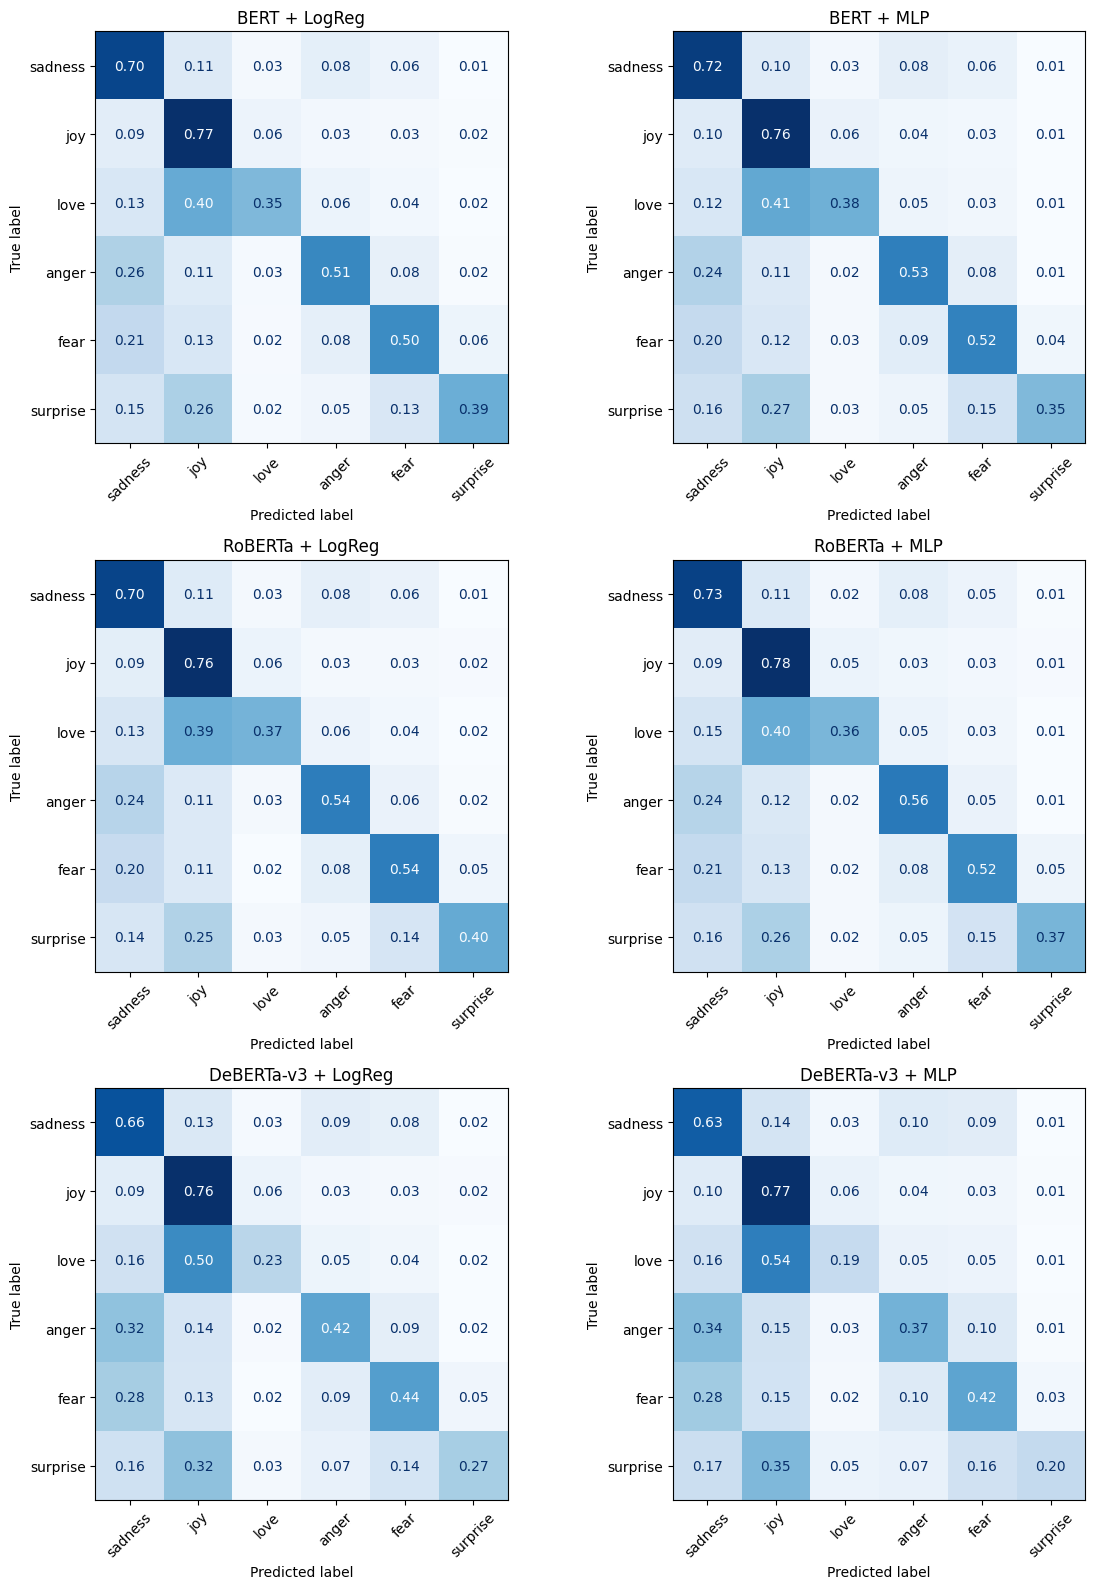

In [22]:
plot_cms("true").savefig(RESULTS / "confusion_normalized.png", dpi=150, bbox_inches="tight")
plt.show()

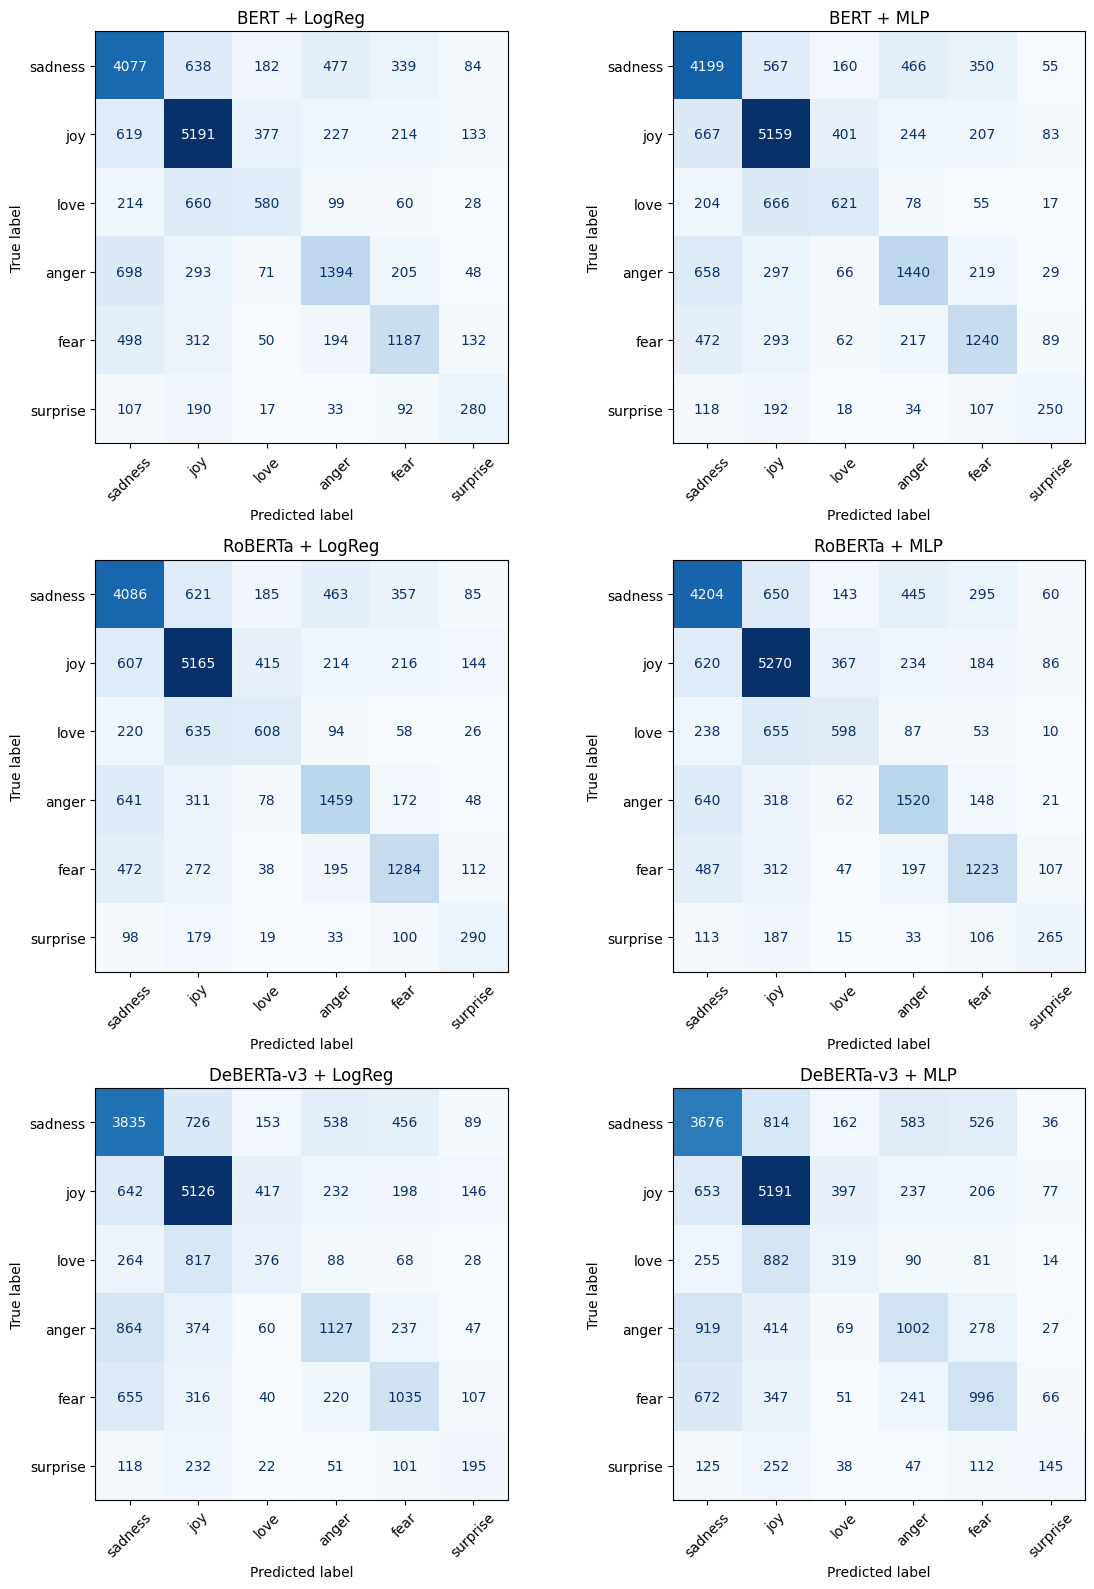

In [23]:
plot_cms(None).savefig(RESULTS / "confusion_counts.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Tabela consolidada

Média ± desvio-padrão entre os 5 folds, ordenada por F1 macro.

In [24]:
summary = pd.DataFrame({
    cfg: {f"{c} {s}": getattr(m[c], s)() for c in m.columns for s in ("mean", "std")}
    for cfg, m in METRICS.items()
}).T.sort_values("F1 mean", ascending=False)
summary.to_csv(RESULTS / "summary.csv")
pd.concat([METRICS[c].assign(config=c) for c in METRICS]).to_csv(RESULTS / "per_fold.csv")

pd.DataFrame({
    c: summary[f"{c} mean"].map("{:.4f}".format) + " ± " + summary[f"{c} std"].map("{:.4f}".format)
    for c in ["acurácia", "precisão", "recall", "F1"]
})

,acurácia,precisão,recall,F1
RoBERTa + MLP,0.6540 ± 0.0100,0.5946 ± 0.0116,0.5523 ± 0.0184,0.5685 ± 0.0160
RoBERTa + LogReg,0.6446 ± 0.0099,0.5721 ± 0.0094,0.5537 ± 0.0089,0.5614 ± 0.0088
BERT + MLP,0.6454 ± 0.0076,0.5802 ± 0.0119,0.5446 ± 0.0132,0.5584 ± 0.0120
BERT + LogReg,0.6355 ± 0.0051,0.5607 ± 0.0116,0.5381 ± 0.0086,0.5472 ± 0.0092
DeBERTa-v3 + LogReg,0.5847 ± 0.0044,0.4905 ± 0.0083,0.4620 ± 0.0075,0.4718 ± 0.0075
DeBERTa-v3 + MLP,0.5665 ± 0.0078,0.4797 ± 0.0239,0.4312 ± 0.0127,0.4429 ± 0.0114


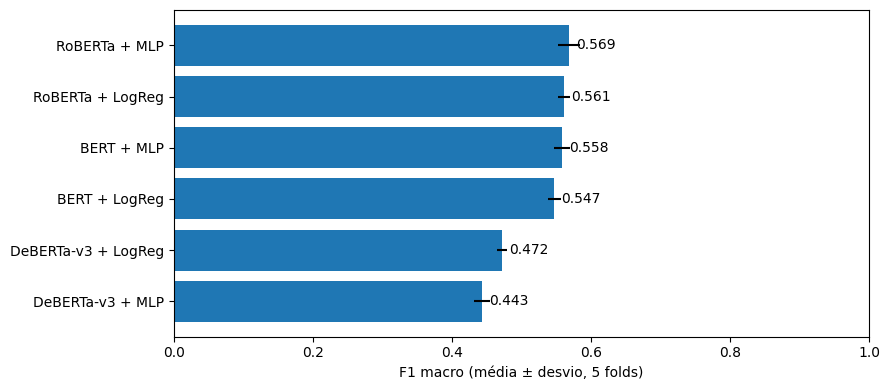

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
order = summary.index[::-1]
ax.barh(order, summary.loc[order, "F1 mean"], xerr=summary.loc[order, "F1 std"], color="tab:blue")
ax.set_xlabel("F1 macro (média ± desvio, 5 folds)")
ax.set_xlim(0, 1)
for i, v in enumerate(summary.loc[order, "F1 mean"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout()
fig.savefig(RESULTS / "f1_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### F1 por classe

Ajuda a ver onde as classes minoritárias (`love`, `surprise`) perdem desempenho.

In [26]:
per_class = pd.DataFrame({
    cfg: precision_recall_fscore_support(y, oof, labels=range(6), zero_division=0)[2]
    for cfg, oof in OOF.items()
}, index=CLASSES).T.loc[summary.index]
per_class.to_csv(RESULTS / "f1_per_class.csv")
per_class.round(3)

,sadness,joy,love,anger,fear,surprise
RoBERTa + MLP,0.695,0.745,0.416,0.582,0.558,0.418
RoBERTa + LogReg,0.686,0.741,0.408,0.565,0.563,0.407
BERT + MLP,0.693,0.740,0.418,0.555,0.545,0.403
BERT + LogReg,0.679,0.739,0.398,0.543,0.531,0.393
DeBERTa-v3 + LogReg,0.630,0.714,0.278,0.454,0.463,0.293
DeBERTa-v3 + MLP,0.608,0.708,0.238,0.408,0.436,0.268


## 10. Discussão resumida

- RoBERTa + MLP teve o melhor F1 macro (0,569), seguido de perto por RoBERTa + LogReg e BERT + MLP. As diferenças entre essas três ficam dentro de cerca de um desvio-padrão entre folds.
- DeBERTa-v3 ficou bem abaixo (F1 de 0,44 a 0,47), apesar de ser o melhor dos três quando ajustado (fine-tuning). O pré-treino por detecção de token substituído (estilo ELECTRA) não produz uma última camada boa para uso congelado com mean pooling.
- O MLP melhora levemente sobre a regressão logística em BERT e RoBERTa (cerca de +0,01 de F1), mas piora no DeBERTa-v3, onde o sinal é mais fraco e o MLP sobreajusta.
- Nas matrizes de confusão, `love` é confundida com `joy` (cerca de 40%) e `surprise` com `joy` e `fear`. `anger` e `fear` vazam para `sadness`. São as classes minoritárias e semanticamente próximas, o que puxa o F1 macro para baixo em relação à acurácia.

A análise completa está no relatório em PDF.